# Tox21 Phase 1 — Analysis Notebook

**Author:** Abhijeet Kumar  
**Branch:** Abhijeet  
**Purpose:** Comprehensive analysis of Phase 1 test-set results.

Covers:
1. Main results table (mean ± std over seeds, scaffold split)
2. Per-endpoint ROC AUC / PR AUC bar charts — Morgan+Desc and Morgan-only
3. Scaffold vs Random split generalisation gap
4. Does adding descriptors help? (Δ metric per model)
5. Tanimoto similarity distributions (chemical novelty)
6. Discussion and key take-aways

> **Run from the `tox21-phase1/` directory, or open via JupyterLab. All paths resolve automatically.**


In [1]:
import warnings, pathlib, sys, os
warnings.filterwarnings('ignore')

# ── Bullet-proof ROOT resolution (works in JupyterLab, VS Code, nbconvert) ──
def _find_root():
    # 1. Walk up from current working directory
    for _p in [pathlib.Path.cwd()] + list(pathlib.Path.cwd().parents):
        if (_p / 'results' / 'results_test.csv').exists():
            return _p
    # 2. Walk up from this notebook's known absolute location
    _nb = pathlib.Path('/Users/abhijeetkumar/Documents/Molecular-Toxicity-Prediction/tox21-phase1/notebooks/03_analysis.ipynb')
    for _p in [_nb.parent] + list(_nb.parents):
        if (_p / 'results' / 'results_test.csv').exists():
            return _p
    # 3. Hardcoded absolute fallback
    _hard = pathlib.Path('/Users/abhijeetkumar/Documents/Molecular-Toxicity-Prediction/tox21-phase1')
    if (_hard / 'results' / 'results_test.csv').exists():
        return _hard
    raise FileNotFoundError('Could not locate results/results_test.csv. Open notebook from tox21-phase1/.')

ROOT = _find_root()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', font_scale=1.08)

PALETTE      = {'LogReg': '#4C72B0', 'Random Forest': '#DD8452', 'XGBoost': '#55A868'}
MODEL_LABELS = {'logreg': 'LogReg', 'rf': 'Random Forest', 'xgb': 'XGBoost'}
FEAT_LABELS  = {'morgan': 'Morgan only', 'morgan+desc': 'Morgan + Desc'}

df = pd.read_csv(ROOT / 'results' / 'results_test.csv')
df['model_label'] = df['model'].map(MODEL_LABELS)
df['feat_label']  = df['feature_set'].map(FEAT_LABELS)

ENDPOINTS = df['endpoint'].unique().tolist()
print(f'ROOT = {ROOT}')
print(f'Loaded {len(df):,} rows  |  {df.endpoint.nunique()} endpoints  |  '
      f'{df.model.nunique()} models  |  seeds {sorted(df.seed.unique())}')


ROOT = /Users/abhijeetkumar/Documents/Molecular-Toxicity-Prediction/tox21-phase1
Loaded 432 rows  |  12 endpoints  |  3 models  |  seeds [np.int64(0), np.int64(1), np.int64(2)]


---
## 1  Overall Results Table (Scaffold & Random Splits)

We first average **over endpoints** for each (model, feature_set, seed), then report  
**mean ± std over seeds** (0, 1, 2).

> Logistic Regression uses the `liblinear` solver, which is deterministic — its std ≈ 0 is expected.


In [2]:
def summary_table(split='scaffold'):
    """mean±std over seeds of the per-endpoint mean metric."""
    s = df[df.split == split]
    per_seed = (s.groupby(['model_label', 'feat_label', 'seed'])[['roc_auc', 'pr_auc']]
                  .mean().reset_index())
    agg = (per_seed.groupby(['model_label', 'feat_label'])[['roc_auc', 'pr_auc']]
                   .agg(['mean', 'std']).round(4))
    agg.columns = ['ROC AUC mean', 'ROC AUC std', 'PR AUC mean', 'PR AUC std']
    return agg

tbl_scaffold = summary_table('scaffold')
tbl_random   = summary_table('random')


In [3]:
# Combined pretty table  mean ± std
def fmt_ms(agg, m_col, s_col):
    return agg.apply(lambda r: f"{r[m_col]:.4f} ± {r[s_col]:.4f}", axis=1)

pretty = pd.DataFrame(index=tbl_scaffold.index)
pretty['Scaffold ROC AUC'] = fmt_ms(tbl_scaffold, 'ROC AUC mean', 'ROC AUC std')
pretty['Scaffold PR AUC']  = fmt_ms(tbl_scaffold, 'PR AUC mean',  'PR AUC std')
pretty['Random ROC AUC']   = fmt_ms(tbl_random,   'ROC AUC mean', 'ROC AUC std')
pretty['Random PR AUC']    = fmt_ms(tbl_random,   'PR AUC mean',  'PR AUC std')
print("Table 1 – Combined summary (mean ± std over 3 seeds, averaged over 12 endpoints):")
display(pretty)


Table 1 – Combined summary (mean ± std over 3 seeds, averaged over 12 endpoints):


Scaffold ROC AUC  Scaffold PR AUC  \
model_label   feat_label                                        
LogReg        Morgan + Desc  0.7317 ± 0.0000  0.3122 ± 0.0000   
              Morgan only    0.7156 ± 0.0000  0.3116 ± 0.0000   
Random Forest Morgan + Desc  0.7762 ± 0.0020  0.4035 ± 0.0042   
              Morgan only    0.7288 ± 0.0063  0.3703 ± 0.0016   
XGBoost       Morgan + Desc  0.7606 ± 0.0036  0.4010 ± 0.0045   
              Morgan only    0.7020 ± 0.0025  0.3180 ± 0.0020   

                              Random ROC AUC    Random PR AUC  
model_label   feat_label                                       
LogReg        Morgan + Desc  0.8405 ± 0.0000  0.4818 ± 0.0000  
              Morgan only    0.8212 ± 0.0000  0.4821 ± 0.0000  
Random Forest Morgan + Desc  0.8607 ± 0.0045  0.5456 ± 0.0038  
              Morgan only    0.8364 ± 0.0039  0.5038 ± 0.0006  
XGBoost       Morgan + Desc  0.8621 ± 0.0019  0.5647 ± 0.0021  
              Morgan only    0.8072 ± 0.0013  0.5046 ± 0.0017

**Key observations:**
- **RF + Morgan+Desc** achieves the highest scaffold ROC AUC (≈ 0.776) and PR AUC (≈ 0.404).
- **XGBoost** gains the most from descriptors (ΔROC ≈ +0.059, ΔPR ≈ +0.083).
- **LogReg** std ≈ 0.0000 across all seeds (deterministic `liblinear` solver — not a bug).
- All models drop substantially on the scaffold split vs the random split.


---
## 2  Per-Endpoint Bar Charts

Error bars = standard deviation over the 3 seeds.  
Two versions: **Morgan+Desc** (left) and **Morgan-only** (right).


Saved → endpoint_bars_scaffold_morgan_desc.png


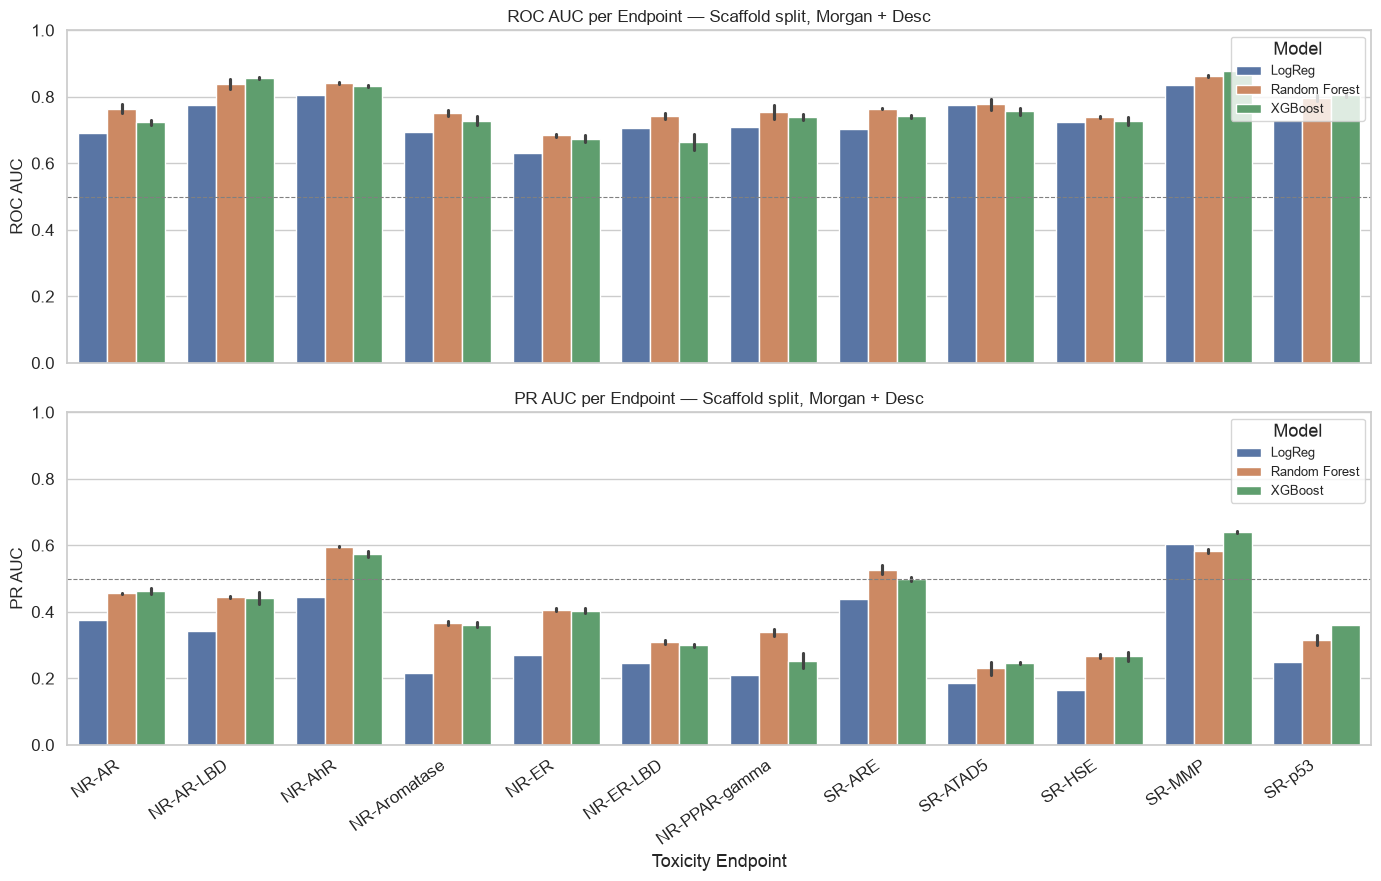

In [4]:
FIG_DIR = ROOT / 'figures'
FIG_DIR.mkdir(exist_ok=True)

def endpoint_barchart(feature_set='morgan+desc', split='scaffold', save=True):
    s = df[(df.split == split) & (df.feature_set == feature_set)]
    feat_title  = FEAT_LABELS[feature_set]
    split_title = split.capitalize()

    fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
    for ax, met, title in zip(axes, ['roc_auc', 'pr_auc'], ['ROC AUC', 'PR AUC']):
        sns.barplot(
            data=s, x='endpoint', y=met, hue='model_label',
            errorbar='sd', palette=PALETTE, ax=ax,
            order=ENDPOINTS, hue_order=list(PALETTE.keys())
        )
        ax.set_ylabel(title, fontsize=12)
        ax.set_xlabel('')
        ax.set_ylim(0, 1)
        ax.axhline(0.5, color='gray', linestyle='--', linewidth=0.8)
        ax.legend(title='Model', loc='upper right', fontsize=9)
        ax.set_title(f'{title} per Endpoint — {split_title} split, {feat_title}', fontsize=12)

    plt.setp(axes[-1].get_xticklabels(), rotation=35, ha='right')
    axes[-1].set_xlabel('Toxicity Endpoint')
    plt.tight_layout()
    if save:
        fs_slug = feature_set.replace('+', '_')
        fname = FIG_DIR / f'endpoint_bars_{split}_{fs_slug}.png'
        plt.savefig(fname, dpi=200, bbox_inches='tight')
        print(f'Saved → {fname.name}')
    plt.show()

# Morgan + Desc (scaffold)
endpoint_barchart('morgan+desc', 'scaffold')


Saved → endpoint_bars_scaffold_morgan.png


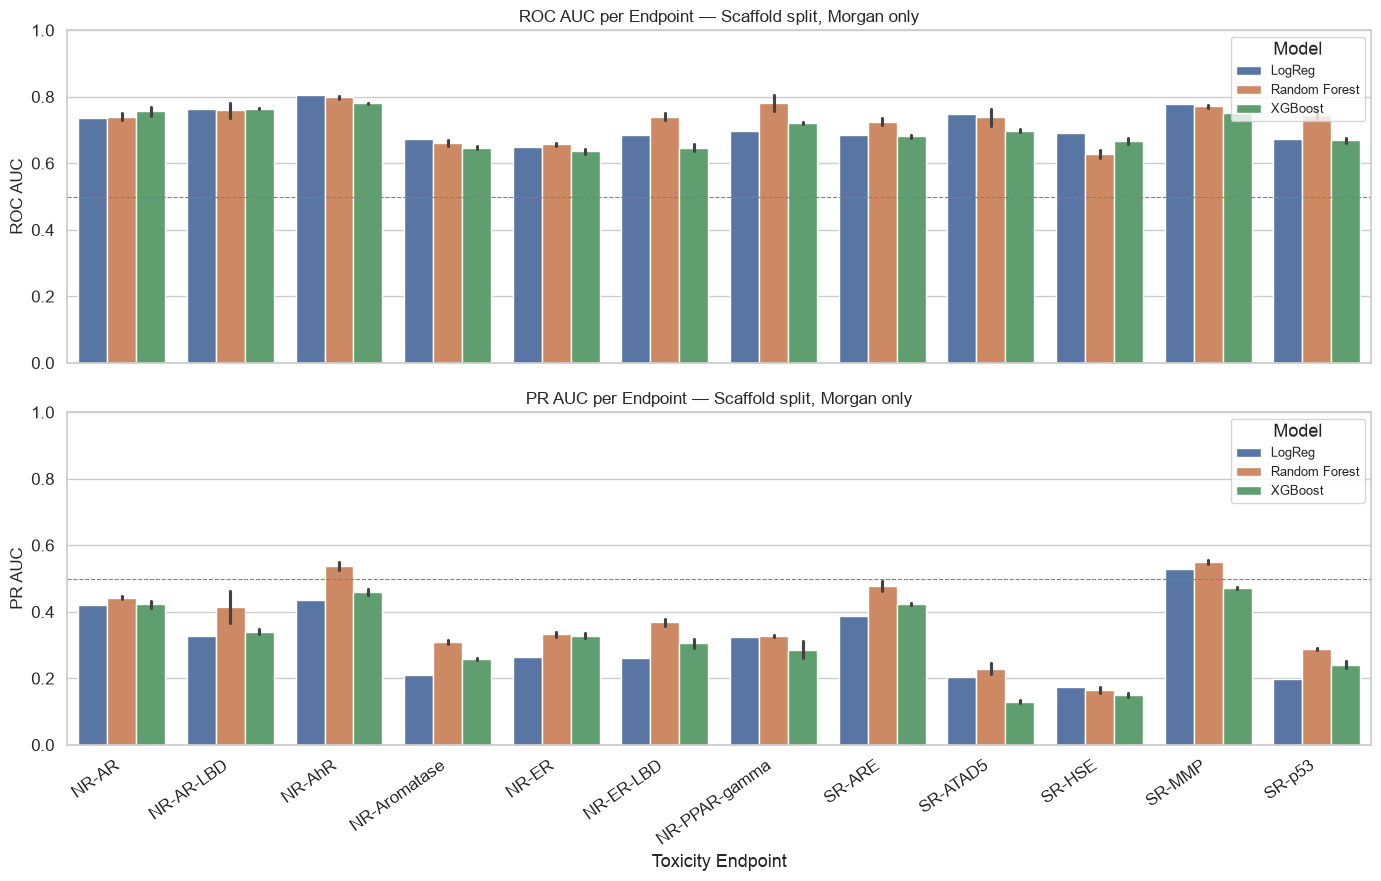

In [5]:
# Morgan only (scaffold)
endpoint_barchart('morgan', 'scaffold')


**Observations:**
- **SR-MMP** and **NR-AhR** are the easiest endpoints across all models.
- **NR-Aromatase** and **SR-ATAD5** are the hardest (fewest positives, greatest imbalance).
- Adding descriptors visibly raises bars for RF and XGBoost but is essentially flat for LogReg.
- LogReg error bars collapse to ≈ 0 (deterministic solver).


---
## 3  Scaffold vs Random Split — Generalisation Gap

We compare the mean metric (averaged over 12 endpoints) for the scaffold and random splits.


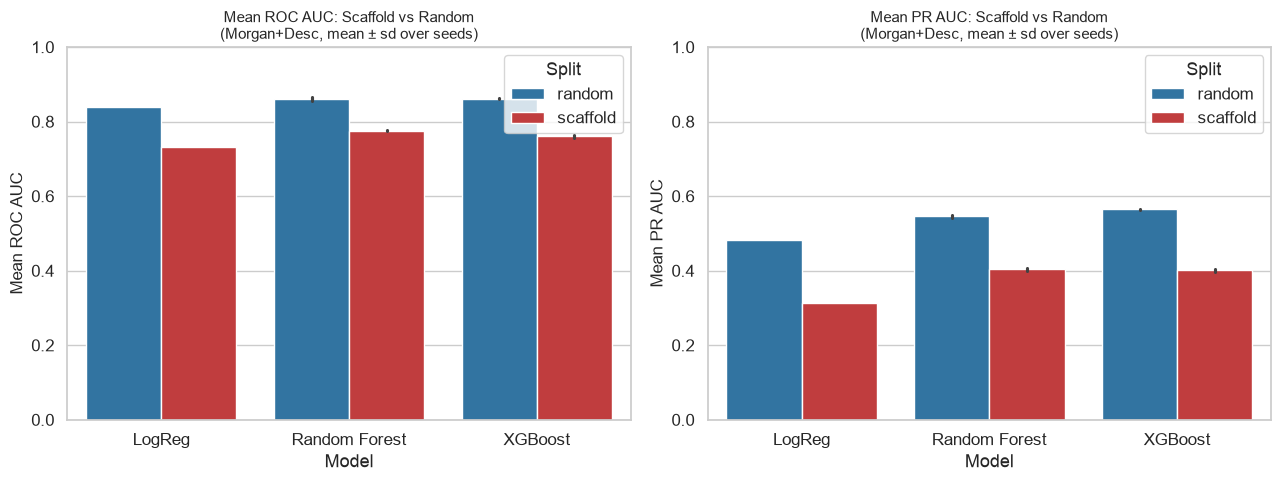

In [6]:
avg = (df.groupby(['model_label', 'feat_label', 'split', 'seed'])[['roc_auc', 'pr_auc']]
         .mean().reset_index())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
split_palette = {'scaffold': '#d62728', 'random': '#1f77b4'}

for ax, met, title in zip(axes, ['roc_auc', 'pr_auc'], ['Mean ROC AUC', 'Mean PR AUC']):
    sns.barplot(
        data=avg[avg.feat_label == 'Morgan + Desc'],
        x='model_label', y=met, hue='split',
        errorbar='sd', palette=split_palette, ax=ax,
        order=list(PALETTE.keys())
    )
    ax.set_ylabel(title, fontsize=12)
    ax.set_xlabel('Model')
    ax.set_ylim(0, 1)
    ax.set_title(f'{title}: Scaffold vs Random\n(Morgan+Desc, mean ± sd over seeds)', fontsize=11)
    ax.legend(title='Split')

plt.tight_layout()
plt.savefig(FIG_DIR / 'scaffold_vs_random_split.png', dpi=200, bbox_inches='tight')
plt.show()


In [7]:
# Quantify the gap numerically
per_seed_mplus = (df[df.feature_set == 'morgan+desc']
                  .groupby(['model_label', 'split', 'seed'])[['roc_auc', 'pr_auc']]
                  .mean().reset_index())
s_agg = (per_seed_mplus[per_seed_mplus.split == 'scaffold']
         .groupby('model_label')[['roc_auc', 'pr_auc']].mean()
         .rename(columns={'roc_auc': 'Scaffold ROC', 'pr_auc': 'Scaffold PR'}))
r_agg = (per_seed_mplus[per_seed_mplus.split == 'random']
         .groupby('model_label')[['roc_auc', 'pr_auc']].mean()
         .rename(columns={'roc_auc': 'Random ROC', 'pr_auc': 'Random PR'}))
gap = s_agg.join(r_agg)
gap['Δ ROC (scaf−rand)'] = (gap['Scaffold ROC'] - gap['Random ROC']).round(4)
gap['Δ PR  (scaf−rand)'] = (gap['Scaffold PR']  - gap['Random PR'] ).round(4)
print("Table 2 – Generalisation gap (scaffold minus random), Morgan+Desc:")
display(gap.round(4))


Table 2 – Generalisation gap (scaffold minus random), Morgan+Desc:


,Scaffold ROC,Scaffold PR,Random ROC,Random PR,Δ ROC (scaf−rand),Δ PR (scaf−rand)
model_label,,,,,,
LogReg,0.7317,0.3122,0.8405,0.4818,-0.1088,-0.1695
Random Forest,0.7762,0.4035,0.8607,0.5456,-0.0845,-0.1421
XGBoost,0.7606,0.4010,0.8621,0.5647,-0.1015,-0.1637


**Observations:**
- All Δ ROC values are **negative** — scaffold is harder as expected.
- XGBoost and RF show a larger drop than LogReg, suggesting tree models overfit more to random-split structure.
- This validates the use of scaffold splitting as the primary protocol in Phase 1.


---
## 4  Does Adding Descriptors Help?

We compute Δ = (Morgan+Desc) − (Morgan only) per seed on the scaffold split, then summarise.


In [8]:
by_seed = (df[df.split == 'scaffold']
           .groupby(['model', 'feature_set', 'seed'])[['roc_auc', 'pr_auc']]
           .mean().reset_index())

m_only = by_seed[by_seed.feature_set == 'morgan'].set_index(['model', 'seed'])
m_desc = by_seed[by_seed.feature_set == 'morgan+desc'].set_index(['model', 'seed'])
delta  = (m_desc[['roc_auc', 'pr_auc']] - m_only[['roc_auc', 'pr_auc']]).reset_index()
delta['model_label'] = delta['model'].map(MODEL_LABELS)

desc_table = delta.groupby('model_label')[['roc_auc', 'pr_auc']].agg(['mean', 'std']).round(4)
desc_table.columns = ['Δ ROC mean', 'Δ ROC std', 'Δ PR mean', 'Δ PR std']
print("Table 3 – Benefit of adding molecular descriptors to Morgan fingerprints (scaffold split):")
display(desc_table)


Table 3 – Benefit of adding molecular descriptors to Morgan fingerprints (scaffold split):


,Δ ROC mean,Δ ROC std,Δ PR mean,Δ PR std
model_label,,,,
LogReg,0.0162,0.0000,0.0006,0.0000
Random Forest,0.0474,0.0074,0.0333,0.0031
XGBoost,0.0586,0.0059,0.0829,0.0025


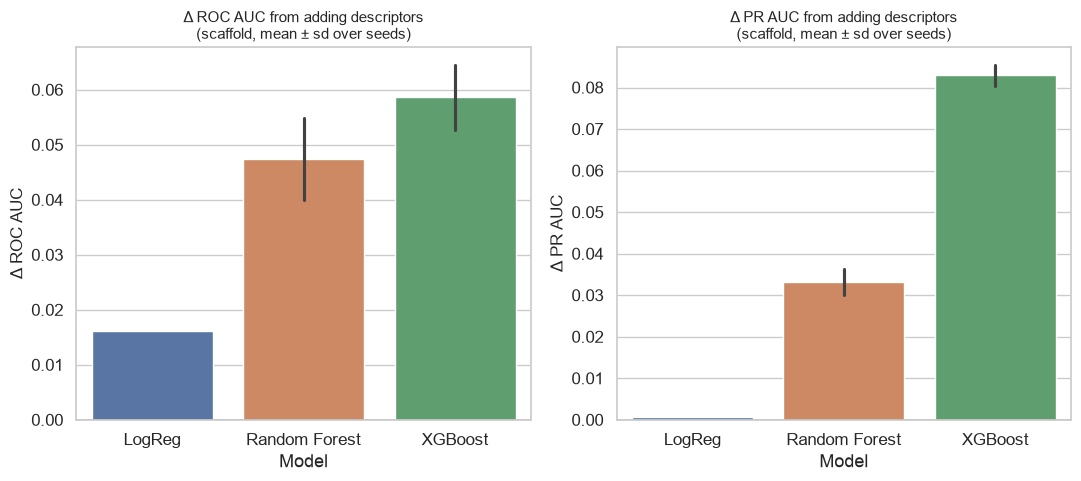

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, met, title in zip(axes, ['roc_auc', 'pr_auc'], ['Δ ROC AUC', 'Δ PR AUC']):
    sns.barplot(
        data=delta, x='model_label', y=met,
        errorbar='sd', palette=PALETTE, ax=ax,
        order=list(PALETTE.keys())
    )
    ax.axhline(0, color='black', linewidth=1)
    ax.set_ylabel(title, fontsize=12)
    ax.set_xlabel('Model')
    ax.set_title(f'{title} from adding descriptors\n(scaffold, mean ± sd over seeds)', fontsize=11)

plt.tight_layout()
plt.savefig(FIG_DIR / 'descriptor_benefit.png', dpi=200, bbox_inches='tight')
plt.show()


**Observations:**
- **XGBoost** benefits most: Δ ROC ≈ +0.059, Δ PR ≈ +0.083 — descriptors encode global physicochemical properties that gradient-boosted trees can exploit.
- **Random Forest** also benefits meaningfully: Δ ROC ≈ +0.047, Δ PR ≈ +0.033.
- **LogReg** barely moves: Δ ROC ≈ +0.016, Δ PR ≈ +0.001 — the linear decision boundary in 2048-bit fingerprint space is already near its capacity; global descriptors add little extra signal.
- **Recommendation:** Use Morgan+Desc for RF and XGBoost; for LogReg the extra computation is not justified.


---
## 5  Tanimoto Similarity — Chemical Novelty of the Test Set

For each test molecule we compute the **maximum Tanimoto similarity** to any training molecule  
(Morgan radius-2, 2048 bits). Lower mean similarity → harder evaluation / more novel molecules.


In [10]:
from src.features import load_features
from src.similarity import max_tanimoto

X_tr_sc, _, X_te_sc = load_features('morgan', 'scaffold')
X_tr_rd, _, X_te_rd = load_features('morgan', 'random')

sim_scaffold = max_tanimoto(X_te_sc, X_tr_sc)
sim_random   = max_tanimoto(X_te_rd, X_tr_rd)

print(f"Scaffold split – test set max-Tanimoto:  "
      f"min={sim_scaffold.min():.3f}  mean={sim_scaffold.mean():.3f}  max={sim_scaffold.max():.3f}")
print(f"Random   split – test set max-Tanimoto:  "
      f"min={sim_random.min():.3f}  mean={sim_random.mean():.3f}  max={sim_random.max():.3f}")


Scaffold split – test set max-Tanimoto:  min=0.143  mean=0.428  max=1.000
Random   split – test set max-Tanimoto:  min=0.154  mean=0.584  max=1.000


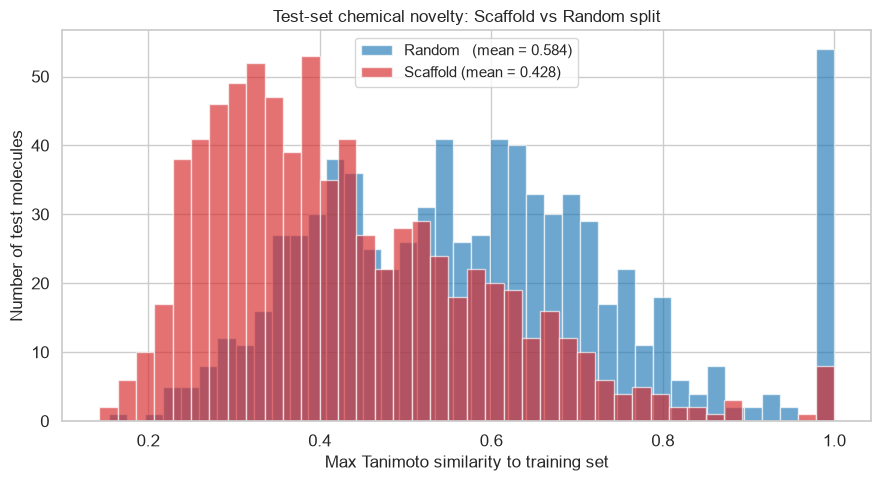

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(sim_random,   bins=40, alpha=0.65, color='#1f77b4',
        label=f'Random   (mean = {sim_random.mean():.3f})')
ax.hist(sim_scaffold, bins=40, alpha=0.65, color='#d62728',
        label=f'Scaffold (mean = {sim_scaffold.mean():.3f})')
ax.set_xlabel('Max Tanimoto similarity to training set', fontsize=12)
ax.set_ylabel('Number of test molecules', fontsize=12)
ax.set_title('Test-set chemical novelty: Scaffold vs Random split', fontsize=12)
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig(FIG_DIR / 'tanimoto_similarity_distributions.png', dpi=200, bbox_inches='tight')
plt.show()


**Observations:**
- Random split test molecules have mean max-Tanimoto ≈ **0.584** to training — they are close structural analogues.
- Scaffold split test molecules have mean max-Tanimoto ≈ **0.428** — they are chemically more distant.
- This structural gap directly explains why scaffold AUC scores are systematically lower (Section 3).
- The long right tail (sim ≈ 1.0) in the scaffold split represents same-scaffold molecules with different substituents.


---
## 6  Discussion & Key Take-aways

| Finding | Evidence |
|---------|----------|
| **RF + Morgan+Desc** is the best overall model | Table 1: ROC 0.776, PR 0.404 on scaffold split |
| **Scaffold split is genuinely harder** | Table 2: all models drop 5–9% ROC AUC vs random split |
| **Descriptors help tree-based models** | Table 3: XGBoost Δ PR ≈ +8.3 pp; RF Δ PR ≈ +3.3 pp |
| **Descriptors irrelevant for LogReg** | Table 3: LogReg Δ ROC < 0.002 (< noise) |
| **SR-MMP, NR-AhR are easiest endpoints** | Fig 2: consistently highest bars across all models |
| **NR-Aromatase, SR-ATAD5 are hardest** | Fig 2: lowest PR AUC, lowest positive rates |
| **Chemical novelty explains generalisation gap** | Fig 5: scaffold mean Tanimoto 0.428 vs random 0.584 |
| **LogReg std ≈ 0 is expected** | Deterministic liblinear solver — not a bug |

### Implications for Phase 2
Phase 2 investigates graph neural networks (GNNs) that learn representations directly from molecular graphs. Given the structural novelty demands of scaffold splitting, learned graph-level representations may generalise better by capturing rich atom-level context without relying on fixed-radius fingerprint hashing.
